# JS09 – Klasifikasi: Tugas 2
## Perbandingan CountVectorizer dan TF-IDF pada Klasifikasi Spam

**Tujuan tugas**

1. Membangun model **Multinomial Naive Bayes** dengan fitur **CountVectorizer** dan **stop words**.
2. Membangun model yang sama dengan fitur **TF-IDF** dan **stop words**.
3. Mengevaluasi dan membandingkan performa kedua representasi teks.
4. Menarik kesimpulan representasi fitur mana yang lebih baik pada dataset `spam.csv`.

**Dataset:** `spam.csv` berisi 5.572 baris SMS berlabel `spam` dan `ham`. Setelah **403 SMS duplikat identik** dihapus, data yang dianalisis berjumlah **5.169 SMS unik** (4.516 ham dan 653 spam). Kelas `ham` jauh lebih banyak (sekitar 87,4%), sehingga akurasi saja tidak cukup; precision, recall, dan F1 untuk kelas spam perlu diperhatikan.

> **Catatan metodologi:** `CountVectorizer`/`TfidfVectorizer` hanya di-fit pada data latih, lalu digunakan untuk mentransformasi data uji. Untuk validasi silang, vectorizer ditempatkan di dalam pipeline agar di-fit ulang pada setiap fold. Ini mencegah *data leakage*. Duplikat dihapus sebelum split agar pesan yang sama tidak muncul di data latih dan data uji sekaligus.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_colwidth", 100)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membaca dan menyiapkan data

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df = df.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"])
df = df.rename(columns={"v1": "Labels", "v2": "SMS"})
df["Labels"] = df["Labels"].map({"spam": 1, "ham": 0})

print("Ukuran data:", df.shape)
print("\nDistribusi kelas:")
print(df["Labels"].value_counts())
print("\nProporsi (%):")
print((df["Labels"].value_counts(normalize=True) * 100).round(2))
df.head()

Ukuran data: (5572, 2)

Distribusi kelas:
Labels
0    4825
1     747
Name: count, dtype: int64

Proporsi (%):
Labels
0    86.59
1    13.41
Name: proportion, dtype: float64


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives around here though"


In [3]:
print("Sebelum deduplikasi:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("Setelah deduplikasi:", df.shape)

Sebelum deduplikasi: (5572, 2)
Setelah deduplikasi: (5169, 2)


Terdapat **403 SMS duplikat identik**. Duplikat dihapus sebelum pemodelan agar pesan yang sama tidak muncul di data latih dan data uji sekaligus (mencegah kebocoran informasi). Setelah deduplikasi tersisa **5.169 SMS unik**: 4.516 ham dan 653 spam.

In [4]:
print("Jumlah nilai kosong:")
print(df.isna().sum())
print("\nJumlah SMS duplikat:", df["SMS"].duplicated().sum())
print("\nStatistik panjang SMS:")
print(df["SMS"].str.len().describe())

Jumlah nilai kosong:
Labels    0
SMS       0
dtype: int64

Jumlah SMS duplikat: 0

Statistik panjang SMS:
count    5169.000000
mean       78.977945
std        58.236293
min         2.000000
25%        36.000000
50%        60.000000
75%       117.000000
max       910.000000
Name: SMS, dtype: float64


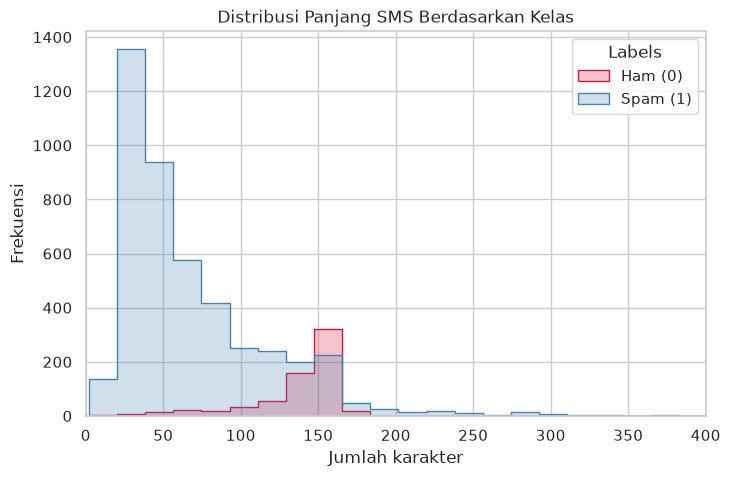

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x=df["SMS"].str.len(),
    hue="Labels",
    bins=50,
    palette={0: "steelblue", 1: "crimson"},
    element="step",
)
plt.title("Distribusi Panjang SMS Berdasarkan Kelas")
plt.xlabel("Jumlah karakter")
plt.ylabel("Frekuensi")
plt.legend(title="Labels", labels=["Ham (0)", "Spam (1)"])
plt.xlim(0, 400)
plt.show()

### 2. Pembagian data

Data dibagi **80% latih dan 20% uji** dengan `random_state=50` dan stratifikasi kelas. Stratifikasi menjaga proporsi spam/ham pada data uji agar evaluasi tidak bias.

In [6]:
X = df["SMS"].values
y = df["Labels"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=50,
    stratify=y,
)

print("Data latih :", len(X_train), "SMS")
print("Data uji   :", len(X_test), "SMS")
print("Kelas latih:", np.bincount(y_train))
print("Kelas uji  :", np.bincount(y_test))

Data latih : 4135 SMS
Data uji   : 1034 SMS
Kelas latih: [3613  522]
Kelas uji  : [903 131]


In [7]:
def metrik_biner(y_true, y_pred):
    return {
        "Precision spam": precision_score(y_true, y_pred),
        "Recall spam": recall_score(y_true, y_pred),
        "F1 spam": f1_score(y_true, y_pred),
    }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_akurasi(vectorizer):
    pipeline = Pipeline([
        ("vectorizer", clone(vectorizer)),
        ("nb", MultinomialNB()),
    ])
    scores = cross_val_score(
        pipeline, X, y, cv=cv, scoring="accuracy", n_jobs=-1
    )
    return scores.mean(), scores.std()

### 3. Model A — CountVectorizer dengan stop words

`CountVectorizer(stop_words="english")` menghapus kata-kata umum bahasa Inggris (misalnya *the*, *is*, *and*) lalu menghitung frekuensi kata yang tersisa. Setiap kata menjadi satu fitur diskrit, sesuai asumsi Multinomial Naive Bayes.

In [8]:
count_vec = CountVectorizer(stop_words="english")

X_train_count = count_vec.fit_transform(X_train)
X_test_count = count_vec.transform(X_test)

count_nb = MultinomialNB()
count_nb.fit(X_train_count, y_train)

pred_train_count = count_nb.predict(X_train_count)
pred_test_count = count_nb.predict(X_test_count)

print("Jumlah fitur:", len(count_vec.get_feature_names_out()))
print("Dimensi X_train:", X_train_count.shape)
print(f"Akurasi latih: {accuracy_score(y_train, pred_train_count):.4f}")
print(f"Akurasi uji  : {accuracy_score(y_test, pred_test_count):.4f}")

Jumlah fitur: 7359
Dimensi X_train: (4135, 7359)
Akurasi latih: 0.9959
Akurasi uji  : 0.9768


In [9]:
print("Confusion Matrix — CountVectorizer + stop words:")
print(confusion_matrix(y_test, pred_test_count))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, pred_test_count, target_names=["ham", "spam"], digits=4))

Confusion Matrix — CountVectorizer + stop words:
[[894   9]
 [ 15 116]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham     0.9835    0.9900    0.9868       903
        spam     0.9280    0.8855    0.9062       131

    accuracy                         0.9768      1034
   macro avg     0.9557    0.9378    0.9465      1034
weighted avg     0.9765    0.9768    0.9766      1034



In [10]:
cv_mean_count, cv_std_count = cv_akurasi(CountVectorizer(stop_words="english"))
print(f"CV accuracy CountVectorizer: {cv_mean_count:.4f} ± {cv_std_count:.4f}")

CV accuracy CountVectorizer: 0.9845 ± 0.0016


### 4. Model B — TF-IDF dengan stop words

`TfidfVectorizer(stop_words="english")` juga menghapus stop words, tetapi bukan sekadar menghitung frekuensi. TF-IDF menggabungkan:

- **TF (Term Frequency)** — seberapa sering kata muncul dalam satu SMS.
- **IDF (Inverse Document Frequency)** — seberapa langka kata tersebut di seluruh korpus.

Kata yang sangat umum di banyak SMS mendapat bobot lebih rendah, sedangkan kata yang khas pada sedikit SMS mendapat bobot lebih tinggi.

In [11]:
tfidf_vec = TfidfVectorizer(stop_words="english")

X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_test_tfidf = tfidf_vec.transform(X_test)

tfidf_nb = MultinomialNB()
tfidf_nb.fit(X_train_tfidf, y_train)

pred_train_tfidf = tfidf_nb.predict(X_train_tfidf)
pred_test_tfidf = tfidf_nb.predict(X_test_tfidf)

print("Jumlah fitur:", len(tfidf_vec.get_feature_names_out()))
print("Dimensi X_train:", X_train_tfidf.shape)
print(f"Akurasi latih: {accuracy_score(y_train, pred_train_tfidf):.4f}")
print(f"Akurasi uji  : {accuracy_score(y_test, pred_test_tfidf):.4f}")

Jumlah fitur: 7359
Dimensi X_train: (4135, 7359)
Akurasi latih: 0.9804
Akurasi uji  : 0.9642


In [12]:
print("Confusion Matrix — TF-IDF + stop words:")
print(confusion_matrix(y_test, pred_test_tfidf))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, pred_test_tfidf, target_names=["ham", "spam"], digits=4))

Confusion Matrix — TF-IDF + stop words:
[[903   0]
 [ 37  94]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham     0.9606    1.0000    0.9799       903
        spam     1.0000    0.7176    0.8356       131

    accuracy                         0.9642      1034
   macro avg     0.9803    0.8588    0.9077      1034
weighted avg     0.9656    0.9642    0.9616      1034



In [13]:
cv_mean_tfidf, cv_std_tfidf = cv_akurasi(TfidfVectorizer(stop_words="english"))
print(f"CV accuracy TF-IDF: {cv_mean_tfidf:.4f} ± {cv_std_tfidf:.4f}")

CV accuracy TF-IDF: 0.9663 ± 0.0007


### 5. Model pembanding — CountVectorizer tanpa stop words

Sebagai konteks tambahan, kita evaluasi `CountVectorizer()` tanpa stop words. Ini bukan bagian wajib tugas, tetapi membantu melihat apakah penghapusan stop words benar-benar meningkatkan performa pada dataset SMS ini.

In [14]:
count_base = CountVectorizer()

X_train_base = count_base.fit_transform(X_train)
X_test_base = count_base.transform(X_test)

base_nb = MultinomialNB()
base_nb.fit(X_train_base, y_train)

pred_test_base = base_nb.predict(X_test_base)

print("Jumlah fitur:", len(count_base.get_feature_names_out()))
print(f"Akurasi latih: {accuracy_score(y_train, base_nb.predict(X_train_base)):.4f}")
print(f"Akurasi uji  : {accuracy_score(y_test, pred_test_base):.4f}")
print(confusion_matrix(y_test, pred_test_base))

Jumlah fitur: 7623
Akurasi latih: 0.9935
Akurasi uji  : 0.9816
[[898   5]
 [ 14 117]]


In [15]:
cv_mean_base, cv_std_base = cv_akurasi(CountVectorizer())
print(f"CV accuracy CountVectorizer tanpa stop words: {cv_mean_base:.4f} ± {cv_std_base:.4f}")

CV accuracy CountVectorizer tanpa stop words: 0.9857 ± 0.0027


### 6. Perbandingan hasil

Tabel berikut merangkum performa ketiga konfigurasi. Fokus utama tugas adalah perbandingan **Count + stop words** dan **TF-IDF + stop words**; baseline Count tanpa stop words disertakan sebagai pembanding.

In [16]:
hasil = pd.DataFrame([
    {
        "Model": "Count + stop words",
        "Jumlah fitur": len(count_vec.get_feature_names_out()),
        "Akurasi latih": accuracy_score(y_train, pred_train_count),
        "Akurasi uji": accuracy_score(y_test, pred_test_count),
        **metrik_biner(y_test, pred_test_count),
        "CV accuracy": cv_mean_count,
    },
    {
        "Model": "TF-IDF + stop words",
        "Jumlah fitur": len(tfidf_vec.get_feature_names_out()),
        "Akurasi latih": accuracy_score(y_train, pred_train_tfidf),
        "Akurasi uji": accuracy_score(y_test, pred_test_tfidf),
        **metrik_biner(y_test, pred_test_tfidf),
        "CV accuracy": cv_mean_tfidf,
    },
    {
        "Model": "Count tanpa stop words",
        "Jumlah fitur": len(count_base.get_feature_names_out()),
        "Akurasi latih": accuracy_score(y_train, base_nb.predict(X_train_base)),
        "Akurasi uji": accuracy_score(y_test, pred_test_base),
        **metrik_biner(y_test, pred_test_base),
        "CV accuracy": cv_mean_base,
    },
])

hasil.round(4)

,Model,Jumlah fitur,Akurasi latih,Akurasi uji,Precision spam,Recall spam,F1 spam,CV accuracy
0,Count + stop words,7359,0.9959,0.9768,0.928,0.8855,0.9062,0.9845
1,TF-IDF + stop words,7359,0.9804,0.9642,1.000,0.7176,0.8356,0.9663
2,Count tanpa stop words,7623,0.9935,0.9816,0.959,0.8931,0.9249,0.9857


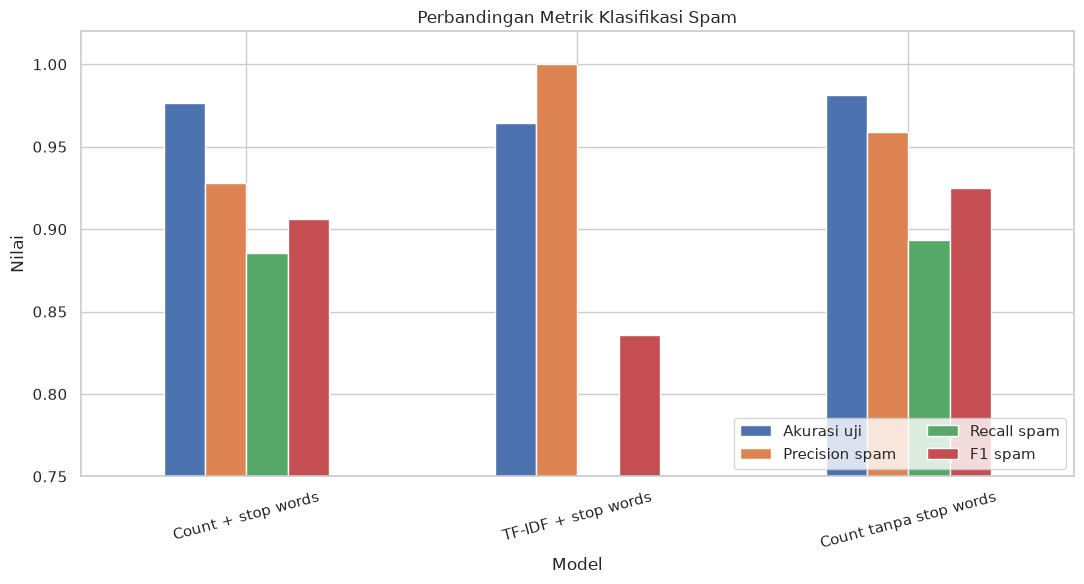

In [17]:
metrik_plot = ["Akurasi uji", "Precision spam", "Recall spam", "F1 spam"]
ax = hasil.set_index("Model")[metrik_plot].plot(
    kind="bar",
    figsize=(11, 6),
    rot=15,
    color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"],
)
ax.set_title("Perbandingan Metrik Klasifikasi Spam")
ax.set_ylabel("Nilai")
ax.set_ylim(0.75, 1.02)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

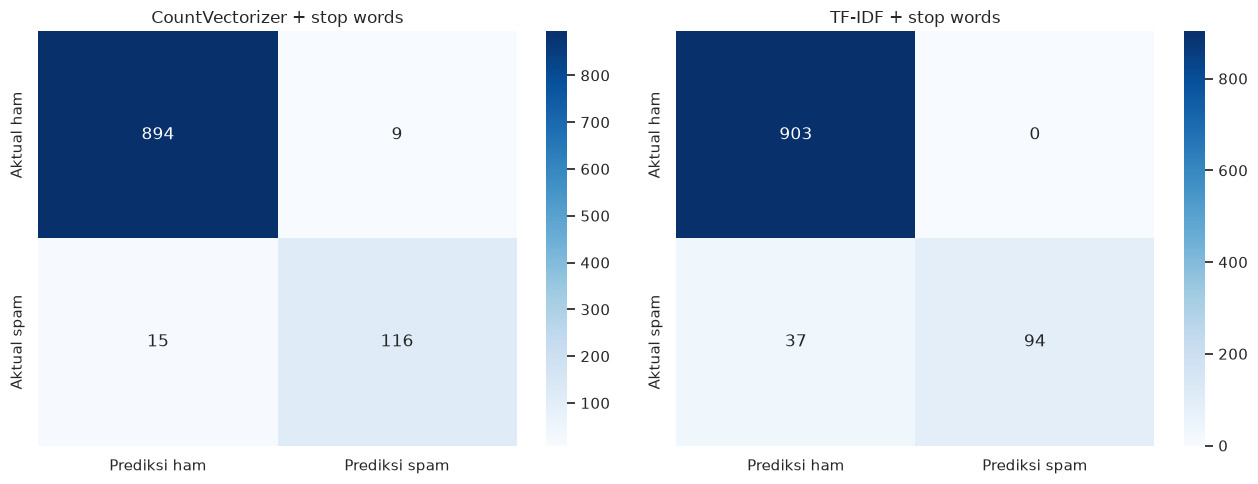

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, pred, title in [
    (axes[0], pred_test_count, "CountVectorizer + stop words"),
    (axes[1], pred_test_tfidf, "TF-IDF + stop words"),
]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Prediksi ham", "Prediksi spam"],
        yticklabels=["Aktual ham", "Aktual spam"],
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

### 7. Analisis kesalahan

TF-IDF memiliki precision spam 1,0 (tidak ada ham yang salah diprediksi sebagai spam), tetapi recall-nya jauh lebih rendah. Artinya, model TF-IDF sangat konservatif: ketika memprediksi spam, hampir selalu benar, tetapi banyak SMS spam yang lolos sebagai ham. CountVectorizer lebih agresif memberi label spam, sehingga recall lebih tinggi tetapi ada beberapa false positive.

In [19]:
def tabel_kesalahan(y_pred, judul):
    errors = pd.DataFrame({
        "SMS": X_test,
        "Aktual": y_test,
        "Prediksi": y_pred,
    })
    errors = errors[errors["Aktual"] != errors["Prediksi"]].copy()
    errors["Aktual"] = errors["Aktual"].map({0: "ham", 1: "spam"})
    errors["Prediksi"] = errors["Prediksi"].map({0: "ham", 1: "spam"})
    print(f"{judul}: {len(errors)} kesalahan")
    return errors.head(5)


tabel_kesalahan(pred_test_count, "CountVectorizer + stop words")

CountVectorizer + stop words: 24 kesalahan


,SMS,Aktual,Prediksi
42,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Jus...,spam,ham
85,"Latest News! Police station toilet stolen, cops have nothing to go on!",spam,ham
131,K..i deleted my contact that why?,ham,spam
185,No pic. Please re-send.,ham,spam
247,"We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us",ham,spam


In [20]:
tabel_kesalahan(pred_test_tfidf, "TF-IDF + stop words")

TF-IDF + stop words: 37 kesalahan


,SMS,Aktual,Prediksi
37,"Download as many ringtones as u like no restrictions, 1000s 2 choose. U can even send 2 yr buddy...",spam,ham
42,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Jus...,spam,ham
75,Bloomberg -Message center +447797706009 Why wait? Apply for your future http://careers. bloomber...,spam,ham
78,Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sor...,spam,ham
85,"Latest News! Police station toilet stolen, cops have nothing to go on!",spam,ham


### 8. Kata yang paling berpengaruh pada kedua representasi

Perbedaan representasi memengaruhi kata mana yang dianggap penting. CountVectorizer memberi bobot pada frekuensi mentah, sedangkan TF-IDF menurunkan bobot kata yang muncul di banyak dokumen. Perbandingan kata khas spam berikut membantu menjelaskan perbedaan recall.

In [21]:
def kata_khas_spam(vectorizer, model, n=12):
    names = np.array(vectorizer.get_feature_names_out())
    diff = model.feature_log_prob_[1] - model.feature_log_prob_[0]
    idx = np.argsort(diff)[-n:][::-1]
    return pd.DataFrame({
        "Kata": names[idx],
        "Skor": diff[idx],
    }).round(3)


kata_count = kata_khas_spam(count_vec, count_nb).rename(
    columns={"Kata": "Count: kata", "Skor": "Count: skor"}
)
kata_tfidf = kata_khas_spam(tfidf_vec, tfidf_nb).rename(
    columns={"Kata": "TF-IDF: kata", "Skor": "TF-IDF: skor"}
)
pd.concat([kata_count, kata_tfidf], axis=1)

,Count: kata,Count: skor,TF-IDF: kata,TF-IDF: skor
0,claim,5.126,claim,3.311
1,prize,4.965,prize,3.244
2,150p,4.738,150p,2.936
3,18,4.420,www,2.864
4,tone,4.420,18,2.748
5,guaranteed,4.257,tone,2.664
6,www,4.181,uk,2.658
7,1000,4.132,guaranteed,2.647
8,cs,4.132,1000,2.585
9,500,4.098,service,2.465


### 9. Analisis dan kesimpulan

**Hasil utama**

| Konfigurasi | Akurasi uji | Precision spam | Recall spam | F1 spam | CV accuracy |
|---|---:|---:|---:|---:|---:|
| Count + stop words | **0,9768** | 0,9280 | **0,8855** | **0,9062** | **0,9845** |
| TF-IDF + stop words | 0,9642 | **1,0000** | 0,7176 | 0,8356 | 0,9663 |
| Count tanpa stop words | **0,9816** | **0,9590** | **0,8931** | **0,9249** | **0,9857** |

**Perbandingan Count vs TF-IDF (keduanya dengan stop words)**

- **CountVectorizer lebih baik** pada akurasi uji (97,68% vs 96,42%), recall spam (88,55% vs 71,76%), F1 spam (0,906 vs 0,836), dan CV accuracy (98,45% vs 96,63%).
- **TF-IDF lebih baik pada precision spam** (1,000 vs 0,928). Model TF-IDF tidak menghasilkan false positive, tetapi melewatkan 37 SMS spam (false negative), sedangkan Count melewatkan 15 spam dengan 9 false positive.
- Pada dataset ini, **CountVectorizer + stop words adalah representasi yang lebih seimbang** karena mampu menangkap lebih banyak spam tanpa terlalu banyak false positive.

**Mengapa TF-IDF tidak lebih baik di sini?**

TF-IDF menurunkan bobot kata yang sering muncul di banyak dokumen. Pada SMS spam, beberapa kata yang sangat khas spam bisa muncul cukup sering across SMS spam, sehingga IDF-nya turun. Akibatnya, sinyal kata tersebut melemah dan model menjadi lebih konservatif. CountVectorizer mempertahankan frekuensi mentah, sehingga kata-kata seperti ajakan membalas, hadiah, atau tautan tetap memberi bobot besar.

**Pengaruh stop words**

Membandingkan Count + stop words dengan Count tanpa stop words menunjukkan bahwa penghapusan stop words justru **menurunkan** performa: akurasi uji turun dari 98,16% menjadi 97,68%, recall turun dari 89,31% menjadi 88,55%, dan F1 turun dari 0,925 menjadi 0,906. Pada SMS yang tidak formal, kata-kata pendek yang sering dianggap stop word (misalnya “u”, “ur”, “im”) bisa tetap membawa informasi gaya bahasa atau pola spam. Karena itu, stop-word removal tidak selalu menguntungkan untuk klasifikasi SMS.

**Kesimpulan**

1. Untuk perbandingan yang diminta, **CountVectorizer + stop words lebih baik daripada TF-IDF + stop words** pada akurasi, recall, F1, dan CV accuracy.
2. TF-IDF unggul pada precision spam, tetapi recall-nya rendah sehingga banyak spam lolos.
3. CountVectorizer tanpa stop words memberi performa terbaik secara keseluruhan pada eksperimen ini, meskipun tidak termasuk konfigurasi wajib tugas.
4. Pemilihan representasi fitur harus mempertimbangkan jenis data dan biaya kesalahan. Jika false positive sangat mahal, TF-IDF bisa dipertimbangkan; jika tujuan utamanya menangkap sebanyak mungkin spam, CountVectorizer lebih sesuai.
5. Untuk pengembangan, dapat dicoba tuning `alpha`, `min_df`/`max_df`, n-gram, atau model linear seperti Logistic Regression/SVM.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS09 – Klasifikasi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi
- `scikit-learn` – Working with text data. https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html
- `scikit-learn` – CountVectorizer dan TfidfVectorizer. https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- `scikit-learn` – Multinomial Naive Bayes. https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes
- Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.